# Práctica 1 - Métodos generativos (Grupo 7)

Generación de caras con un subconjunto de CelebAMask-HQ (30.000 imágenes de 64x64). Dos modelos entrenados desde cero, con **las mismas decisiones de diseño** y el mismo reparto de datos, para que la comparación entre ellos sea justa:

- **Parte A**: Autoencoder (AE) convolucional.
- **Parte B**: Variational Autoencoder (VAE).
- **Parte C**: comparación de los dos, fusión de caras y registro de pruebas.

La idea que recorre el notebook: **el VAE es el AE más un latente probabilístico**. Los dos comparten la red base, la pérdida de reconstrucción, el entrenamiento y el muestreo del latente (sección 4). Lo único que cambia es lo que define a cada modelo: el AE codifica cada imagen a un punto `z` y el VAE a una distribución, con un término KL en la pérdida.

Las partes A y B siguen los mismos pasos: modelo, entrenamiento, reconstrucciones, generar caras, CSV para Kaggle y FID local. Se ejecuta de arriba abajo; cada parte genera su propio CSV (`submission_final_ae.csv` y `submission_final_vae.csv`).

In [1]:
import os
import gc
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.mixture import GaussianMixture

SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 1. Datos

30.000 caras de 64x64 en `CelebAMask/images/0.jpg ... 29999.jpg`. Las pasamos a RGB y a [0, 1] (la salida de los decoders es una sigmoide, así que los datos tienen que estar en ese rango). Separamos 90 % para entrenar y 10 % para validación. **Los dos modelos usan exactamente este reparto.** La validación sirve para saber cuándo parar y para medir reconstrucciones, no se usa para generar.

In [2]:
DATA_DIR = "CelebAMask/images"
N_IMAGES = 30000

x = np.array([cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{i}.jpg"), cv2.COLOR_BGR2RGB) for i in range(N_IMAGES)],
             dtype="float32") / 255.0
print(x.shape, x.min(), x.max())      # (30000, 64, 64, 3) 0.0 1.0

# split 90 / 10 sobre índices barajados
idx = np.random.permutation(len(x))
n_val = int(0.1 * len(x))
x_val, x_train = x[idx[:n_val]], x[idx[n_val:]]
del x                                  
print(x_train.shape, x_val.shape)

(30000, 64, 64, 3) 0.0 1.0
(27000, 64, 64, 3) (3000, 64, 64, 3)


## 2. Herramientas comunes (FID, CSV)

**FID.** La competición puntúa con **FID** (más bajo es mejor): compara las caras generadas con las reales usando los rasgos de una red InceptionV3. Para no gastar subidas lo calculamos en local con el InceptionV3 de Keras (ImageNet), usado **solo para evaluar** (no se entrena ni se ajusta).

- Los valores **no coinciden** con los de Kaggle (no es el Inception oficial), pero sirven para comparar modelos entre sí. 
- Con 200 imágenes el FID es ruidoso y sale más alto de lo normal; con 1000 es más estable, y es el que usamos para decidir.
- La conversión a gris usa los pesos de luminancia (0,299 / 0,587 / 0,114), los mismos que `cv2` al generar el CSV.

**CSV.** Kaggle evalúa en **escala de grises**: pasamos las 200 caras a uint8, las convertimos a gris y aplanamos cada una en 4096 píxeles.

In [3]:
REF_N = 3000     # caras reales de train que usamos como referencia
N_FID = 1000     # caras generadas para el FID estable

# InceptionV3 de ImageNet sin la capa final: devuelve un vector de 2048 por imagen
inception = keras.applications.InceptionV3(include_top=False, pooling="avg", weights="imagenet",
                                           input_shape=(299, 299, 3))


def rasgos(imgs, batch=16):
    """imgs (N, 64, 64, 3) en [0, 1]. Igual que el evaluador: gris de 8 bits -> 3 canales -> 299x299."""
    g = np.round(imgs @ np.array([0.299, 0.587, 0.114]) * 255).clip(0, 255) / 255.0
    out = []
    for i in range(0, len(g), batch):
        b = np.repeat(g[i:i + batch, ..., None], 3, axis=-1).astype("float32")
        b = tf.image.resize(b, (299, 299), method="bilinear")
        out.append(inception.predict(keras.applications.inception_v3.preprocess_input(b * 255.0), verbose=0))
    return np.concatenate(out)


def estadisticos(f):
    return f.mean(axis=0), np.cov(f, rowvar=False)


def fid_entre(mu1, s1, mu2, s2):
    """FID = |mu1 - mu2|^2 + Tr(S1 + S2 - 2 (S1 S2)^(1/2)). La traza de la raíz sale de los autovalores de S1 S2."""
    eig = np.linalg.eigvals(s1 @ s2)
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1) + np.trace(s2) - 2 * np.sqrt(np.clip(eig.real, 0, None)).sum())


mu_ref, sig_ref = estadisticos(rasgos(x_train[:REF_N]))      # estadísticos de las caras reales


def fid_local(imgs):
    mu_i, sig_i = estadisticos(rasgos(imgs))
    return fid_entre(mu_i, sig_i, mu_ref, sig_ref)


# Referencias: el mejor y el peor valor posibles con este método de medida
fid_suelo = fid_local(x_val[:200])
fid_ruido = fid_local(np.random.default_rng(SEED).random((200, 64, 64, 3)).astype("float32"))
print(f"Referencia reales (200 imgs):  {fid_suelo:.1f}")
print(f"Referencia ruido  (200 imgs):  {fid_ruido:.1f}")

If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.

If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.



Referencia reales (200 imgs):  35.8
Referencia ruido  (200 imgs):  582.4


In [4]:
N_SAMPLES = 200


def guardar_csv(faces, ruta):
    """Caras (N, 64, 64, 3) en [0, 1] -> CSV de Kaggle: ID + 4096 píxeles en escala de grises, sin columna Usage."""
    faces_u8 = np.round(faces * 255).astype("uint8")
    gray = np.array([cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in faces_u8])    # (N, 64, 64)
    df = pd.DataFrame(gray.reshape(len(faces), -1))
    df.insert(0, "ID", range(1, len(faces) + 1))
    df.to_csv(ruta, index=False)
    print(ruta, "guardado | shape:", df.shape)         # (200, 4097)


def fid_del_csv(ruta):
    """FID local de un CSV, leído tal cual lo lee Kaggle (200 imágenes en gris)."""
    px = pd.read_csv(ruta).iloc[:, 1:].values.reshape(-1, 64, 64) / 255.0
    return fid_local(np.repeat(px[..., None], 3, axis=-1))

## 3. Decisiones comunes a los dos modelos

Para que la comparación AE vs VAE tenga sentido, los dos comparten todo lo que no define a cada uno. Las decisiones salen del VAE del grupo, que es el que mejor puntuación ha dado en Kaggle, y se aplican también al AE.

| Decisión | Valor (AE y VAE) |
|---|---|
| Red base | Encoder: 3 convs `kernel 4, stride 2` (64, 128, 256 filtros, `GroupNorm -> LeakyReLU`) + `Dense(512)`. Decoder: el espejo |
| Latente | 128 números |
| Pérdida de reconstrucción | `0.8 · (1 - SSIM) + 0.2 · L1`, multiplicada por 1000 |
| Entrenamiento | Adam lr 2e-4, lotes de 128, hasta 50 épocas, `EarlyStopping` (paciencia 6) y `ReduceLROnPlateau` |
| Muestreo del latente | Mezcla de gaussianas con `K` y temperatura `T` elegidas por FID |

**Qué cambia entre ellos.** El AE termina el encoder con una `Dense(128)` (el latente) y minimiza solo la pérdida de reconstrucción. El VAE termina con dos cabezas (`z_mean`, `z_log_var`), muestrea `z` con el *reparameterization trick* y suma `beta · KL` a la pérdida.

### Por qué cada decisión

Lo "vanilla" de clase es: convoluciones + capas densas, decoder espejo con deconvoluciones, pérdida MSE o BCE y, en el VAE, `z ~ N(0, I)` con la KL con peso 1. Todo lo de abajo se aparta de eso en algo, así que hay que poder justificarlo y decir que **no está en clase** donde se indique. Varios números (los pesos 0.8 / 0.2, `beta`, lr, `K`...) los eligió el compañero que hizo el VAE probando, no salen de ninguna teoría: conviene preguntarle qué alternativas probó.

**1. Pérdida: SSIM + L1 en vez de MSE**
- *El problema del MSE*: cuando la red no está segura de un detalle (mechones de pelo, dientes, fondo), lo que minimiza el error cuadrático medio es el **promedio** de las posibilidades, es decir, una imagen borrosa. Y el FID castiga las caras borrosas.
- *SSIM (structural similarity)*: compara dos imágenes por ventanitas locales mirando brillo, contraste y **estructura** (bordes, texturas). Vale 1 si son iguales, así que usamos `1 - SSIM` como error. Como mira la estructura, penaliza una cara sin bordes mucho más que el MSE.
- *L1*: error absoluto medio por píxel. Se deja una parte para que el brillo y el color no se desvíen, y penaliza menos los errores grandes que el MSE.
- *Pesos 0.8 / 0.2*: casi todo estructura y un poco de L1.
- *Por 1000*: solo un factor de escala. SSIM y L1 valen del orden de 0,1 y la KL del VAE vale cientos; multiplicando, la reconstrucción queda en el orden de 100-200 y el peso `beta` se maneja con una escala razonable.
- En el AE es la pérdida entera; en el VAE se le suma `beta · KL`.

**2. `beta = 0,001` en el VAE**
- La KL empuja los `z` hacia `N(0, I)`. Con `beta = 1` eso permite generar sacando `z ~ N(0, I)`, pero limita la información que cabe en `z` y las caras salen más borrosas.
- Con `beta = 0,001` la KL casi no pesa: al final del entrenamiento vale ~717 y la reconstrucción ~171 (en validación ~713 y ~203), así que `beta · KL` ≈ 0,7, **menos del 1 % de la pérdida**. El VAE reconstruye bien (casi como un AE), pero su latente **no** se parece a `N(0, I)`.
- Consecuencia: no se puede generar con `z ~ N(0, I)`; hay que ajustar una distribución a los latentes reales (punto 5). Lo que le queda de VAE es que durante el entrenamiento se muestrea `z` con ruido, lo que hace al decoder tolerante a pequeñas variaciones del latente.
- Es un compromiso entre fidelidad a la teoría y calidad de las caras: **no es un VAE de libro**, y hay que decirlo claro.

**3. Red base**
- *Kernel 4 con stride 2*: el kernel es divisible entre el stride, así que al ampliar las zonas de la imagen se solapan por igual y se evitan las cuadrículas que a veces salen con kernel 3.
- *GroupNorm en vez de BatchNorm*: normalizar las activaciones estabiliza el entrenamiento. BatchNorm usa la media y la varianza del lote, y al generar con `z` nuevos usa estadísticas acumuladas, así que el decoder se puede comportar distinto al entrenar y al generar. GroupNorm normaliza dentro de cada imagen, por grupos de canales (8), y no depende del lote.
- *LeakyReLU en vez de ReLU*: ReLU da gradiente 0 a lo negativo y puede dejar neuronas "muertas"; LeakyReLU deja pasar una fracción (0,2).
- *`use_bias=False` en las convoluciones*: la normalización que viene después ya incluye su propio desplazamiento, así que el sesgo sobra.
- *`Dense(512)` intermedia en el encoder*: reduce 16384 -> 512 -> 128 en vez de 16384 -> 128 directo. Es la parte de "capas totalmente conectadas que combinan las características" de clase, con un escalón más. Decisión del compañero, no comparada aquí con quitarla.
- *Latente de 128*: 12288 valores de entrada comprimidos casi 100 veces (el latente tiene que ser mucho menor que la entrada). Es un valor habitual para caras.
- *Sigmoide al final y `z_log_var`*: lo normal. La sigmoide deja la salida en [0, 1] como los datos, y se predice `log(sigma^2)` para que `sigma` sea siempre positivo.

**4. Entrenamiento**
- *Adam con lr 2e-4*: más bajo que el 1e-3 habitual, pasos más pequeños: más estable con esta pérdida.
- *`EarlyStopping`* (paciencia 6): para si la validación no mejora en 6 épocas y se queda con los mejores pesos, así no hace falta adivinar el número de épocas. *`ReduceLROnPlateau`*: baja el lr a la mitad si la validación se estanca 2 épocas.
- *Lotes de 128*: más estables que los pequeños; si la GPU no los aguanta, se baja a 64.

**5. Muestreo con mezcla de gaussianas (GMM) y temperatura**
- En clase se explica *por qué* un AE no genera: su espacio latente es discontinuo y no se conoce `p(z)`, así que un `z` al azar cae en zonas que el decoder no ha visto. El VAE lo arregla con el prior `N(0, I)`; como el nuestro no cumple eso (punto 2), hacemos algo parecido a posteriori: mirar **dónde caen las caras reales** y muestrear de ahí.
- Ajustamos una mezcla de `K` gaussianas con covarianza completa a los `z` de train (el GMM sale en clase como modelo generativo clásico, con EM, pero no aplicado al latente). La covarianza completa recoge que las dimensiones del latente están relacionadas entre sí. Con `K = 1` es una sola gaussiana.
- *Temperatura `T`*: acerca cada muestra al centro de su gaussiana (`T = 1` no cambia nada). `T < 1` da caras más "típicas" y menos variadas.
- Se prueban varias `K` y `T` y se elige la de menor FID con 1000 caras. En nuestra ejecución, con el mejor `T` de cada `K`, el FID de 1000 caras fue 89,6 / 82,0 / 76,9 en el AE y 89,8 / 80,0 / 78,1 en el VAE para `K` = 1 / 8 / 24: **la mejora viene de pasar de una a varias gaussianas** (de ~90 a ~77-78, un 13-14 %), de 8 a 24 aporta otros 2-5 puntos, y `T` mueve el FID 1-2 puntos.
- La búsqueda usa el mismo FID que luego se informa, así que el valor elegido sale algo optimista: lo reevaluamos con otra muestra. El latente se ajusta solo con imágenes de train.

**6. FID local con InceptionV3**: la red preentrenada se usa solo para **medir**, sin entrenarla ni ajustarla, así que no entra en la prohibición de fine-tuning del enunciado. No coincide con el FID de Kaggle, pero ordena bien los modelos.

In [5]:
LATENT_DIM = 128
LR = 2e-4
BATCH = 128            # si da error de memoria en la GPU, bajar a 64 (en los dos modelos)
EPOCHS = 50

K_GRID = (1, 8, 24)
T_GRID = (0.7, 0.8, 0.9, 1.0)


def perdida_reconstruccion(x, x_hat):
    """Pérdida de reconstrucción común: 0.8 * (1 - SSIM) + 0.2 * L1, por 1000."""
    l1 = tf.reduce_mean(tf.abs(x - x_hat), axis=(1, 2, 3))
    ssim = tf.image.ssim(x, x_hat, max_val=1.0)
    return (0.8 * tf.reduce_mean(1.0 - ssim) + 0.2 * tf.reduce_mean(l1)) * 1000.0


def cuerpo_encoder(entrada):
    """Red base del encoder: 64x64x3 -> vector de 512. Igual en el AE y en el VAE."""
    h = layers.Conv2D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(entrada)   # 64x64x3   -> 32x32x64
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    h = layers.Conv2D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(h)        # 32x32x64  -> 16x16x128
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    h = layers.Conv2D(256, kernel_size=4, strides=2, padding="same", use_bias=False)(h)        # 16x16x128 -> 8x8x256
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    h = layers.Flatten()(h)                                                                    # 8x8x256 -> 16384
    return layers.Dense(512, activation="relu")(h)                                             # 16384 -> 512


def crear_decoder(nombre):
    """Decoder: vector de 128 -> 64x64x3. Igual en el AE y en el VAE."""
    dec_in = layers.Input(shape=(LATENT_DIM,), name="decoder_input")

    h = layers.Dense(8 * 8 * 256, use_bias=False)(dec_in)                                      # 128 -> 16384
    h = layers.Reshape((8, 8, 256))(h)                                                         # 16384 -> 8x8x256
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    h = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same", use_bias=False)(h)   # 8x8x256   -> 16x16x128
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    h = layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding="same", use_bias=False)(h)    # 16x16x128 -> 32x32x64
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.LeakyReLU(0.2)(h)

    dec_out = layers.Conv2DTranspose(3, kernel_size=4, strides=2, padding="same", activation="sigmoid")(h)   # 32x32x64 -> 64x64x3
    return keras.Model(dec_in, dec_out, name=nombre)


def callbacks_comunes():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]


def dataset(x_array):
    """Pares (x, x) en lotes. Los datos se quedan en la CPU y a la GPU solo llegan los lotes: si pasamos el array
    entero a fit(), TensorFlow intenta copiarlo a la GPU (1,3 GB) y con 2 GB falla."""
    with tf.device("/CPU:0"):
        return (tf.data.Dataset.from_tensor_slices(x_array)
                .shuffle(1024, seed=SEED).map(lambda x: (x, x)).batch(BATCH).prefetch(tf.data.AUTOTUNE))


train_ds, val_ds = dataset(x_train), dataset(x_val)


def ajustar_mezcla(z, K):
    """Ajusta una mezcla de K gaussianas (covarianza completa) a los latentes z.
    reg_covar suma una constante pequeña a la diagonal para evitar covarianzas casi singulares."""
    return GaussianMixture(K, covariance_type="full", reg_covar=1e-4, random_state=0).fit(z)


def muestrear(decoder, gmm, n, T=1.0, seed=SEED):
    """n caras nuevas: z de la mezcla (acercado a su centro con la temperatura T) -> decoder."""
    gmm.random_state = seed                        # sample() usa el generador del propio gmm
    z, comp = gmm.sample(n)
    centros = gmm.means_[comp]
    z = centros + T * (z - centros)
    return np.clip(decoder.predict(z.astype("float32"), batch_size=128, verbose=0), 0, 1)


def buscar_muestreo(decoder, z_train):
    """Prueba todas las combinaciones (K, T) con el FID de N_FID caras y devuelve la mejor."""
    gmms, resultados = {}, {}
    for K in K_GRID:
        gmms[K] = ajustar_mezcla(z_train, K)
        for T in T_GRID:
            resultados[(K, T)] = fid_local(muestrear(decoder, gmms[K], N_FID, T, seed=SEED + 1))
            print(f"K={K:>2}  T={T:.1f}  ->  FID({N_FID}) = {resultados[(K, T)]:.2f}")
    K, T = min(resultados, key=resultados.get)
    print(f"\n>>> Mejor configuración: K={K}, T={T}  (FID {resultados[(K, T)]:.2f}) <<<")
    return gmms[K], K, T, resultados

# Parte A. Autoencoder (AE)

## 4. Modelo

La red base de la sección 3 y, al final del encoder, una `Dense` de 128 sin activación que es el **latente `z`**. Pasamos de 12288 valores a 128. El decoder es el mismo que el del VAE. Compilamos con la pérdida de reconstrucción común (SSIM + L1) y Adam con lr 2e-4: el AE no tiene KL, así que su pérdida es solo la reconstrucción.

In [6]:
ae_in = keras.Input(shape=(64, 64, 3))
z = layers.Dense(LATENT_DIM)(cuerpo_encoder(ae_in))            # 512 -> 128 (latente, sin activación)

encoder = keras.Model(ae_in, z, name="encoder")
decoder = crear_decoder("decoder")

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_94 (Conv2D)              │ (None, 32, 32, 64)     │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization             │ (None, 32, 32, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_95 (Conv2D)              │ (None, 16, 16, 128)    │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_1           │ (None, 16, 16, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_96 (Conv2D)              │ (None, 8, 8, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_2           │ (None, 8, 8, 256)      │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,114,112 (34.77 MB)

 Trainable params: 9,114,112 (34.77 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16384)          │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_3           │ (None, 8, 8, 256)      │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_4           │ (None, 16, 16, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_5           │ (None, 32, 32, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,756,483 (10.52 MB)

 Trainable params: 2,756,483 (10.52 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
ae_full_in = keras.Input(shape=(64, 64, 3))
autoencoder = keras.Model(ae_full_in, decoder(encoder(ae_full_in)), name="autoencoder")

# Compilación: pérdida de reconstrucción común y Adam
autoencoder.compile(optimizer=keras.optimizers.Adam(LR), loss=perdida_reconstruccion)

autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 128)            │     9,114,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 64, 64, 3)      │     2,756,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,870,595 (45.28 MB)

 Trainable params: 11,870,595 (45.28 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Entrenamiento

El objetivo del AE es la propia entrada, por eso el dataset da pares `(x, x)`. Mismos lotes, épocas y callbacks que el VAE: `EarlyStopping` para si la validación no mejora en 6 épocas y se queda con los mejores pesos; `ReduceLROnPlateau` baja el learning rate a la mitad si se estanca 2 épocas.

Epoch 1/50


210/211 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 561.8362

211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - loss: 561.3197

211/211 ━━━━━━━━━━━━━━━━━━━━ 45s 137ms/step - loss: 452.8501 - val_loss: 331.8344 - learning_rate: 2.0000e-04
Epoch 2/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 297.7957 - val_loss: 276.9180 - learning_rate: 2.0000e-04
Epoch 3/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 261.0572 - val_loss: 251.1437 - learning_rate: 2.0000e-04
Epoch 4/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 241.5030 - val_loss: 236.4722 - learning_rate: 2.0000e-04
Epoch 5/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 229.1654 - val_loss: 228.7975 - learning_rate: 2.0000e-04
Epoch 6/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 220.6916 - val_loss: 222.3436 - learning_rate: 2.0000e-04
Epoch 7/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 214.6023 - val_loss: 219.1472 - learning_rate: 2.0000e-04
Epoch 8/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 210.2130 - val_loss: 215.1881 - learning_rate: 2.0000e-04
Epoch 9/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/s

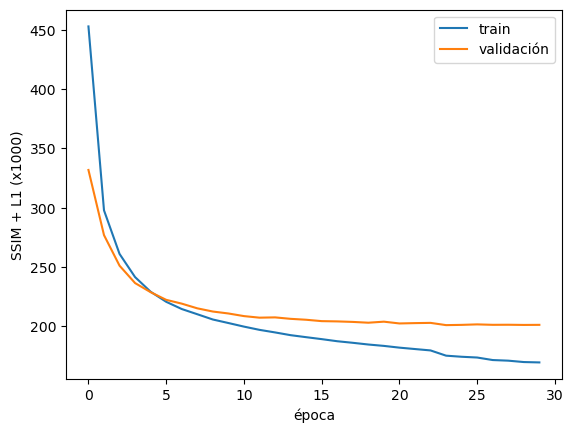

In [8]:
history_ae = autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_comunes(),
)

plt.plot(history_ae.history["loss"], label="train")
plt.plot(history_ae.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("SSIM + L1 (x1000)"); plt.legend(); plt.show()

## 6. Reconstrucciones

Arriba la imagen original de validación, abajo lo que reconstruye el AE.

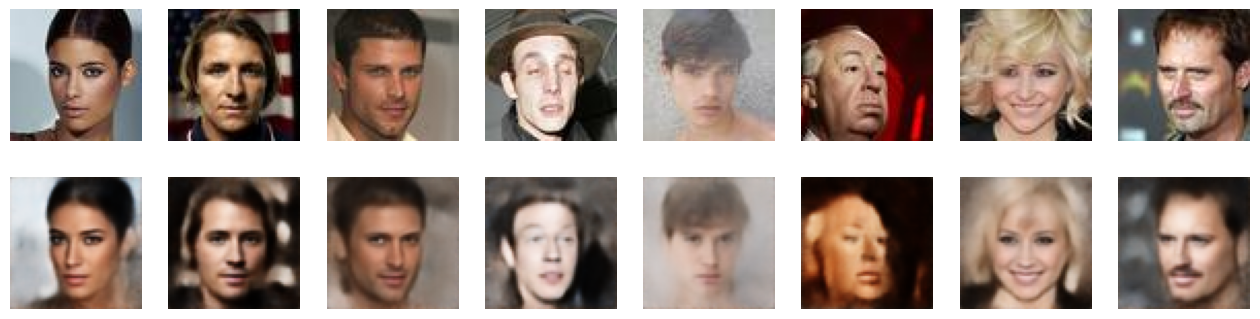

In [9]:
rec = autoencoder.predict(x_val[:8], verbose=0)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(x_val[i]); axes[1, i].imshow(np.clip(rec[i], 0, 1))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.show()

## 7. Generar caras

Muestreo de la sección 3: codificamos las 27.000 imágenes de train, probamos las combinaciones de `K` y `T` y nos quedamos con la de menor FID de 1000 caras. Con `K = 1` sería una sola gaussiana con la media y la covarianza de los `z`. La búsqueda usa el mismo FID que luego se informa, así que el valor elegido sale algo optimista: lo reevaluamos con otra muestra.

In [10]:
z_ae_train = encoder.predict(x_train, batch_size=256, verbose=0)
print("Latentes de train:", z_ae_train.shape)

gmm_ae, AE_K, AE_T, resultados_ae = buscar_muestreo(decoder, z_ae_train)


If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.

If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.



Latentes de train: (27000, 128)


K= 1  T=0.7  ->  FID(1000) = 91.48
K= 1  T=0.8  ->  FID(1000) = 89.99
K= 1  T=0.9  ->  FID(1000) = 89.61
K= 1  T=1.0  ->  FID(1000) = 90.15


/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


K= 8  T=0.7  ->  FID(1000) = 83.05
K= 8  T=0.8  ->  FID(1000) = 82.05
K= 8  T=0.9  ->  FID(1000) = 82.03
K= 8  T=1.0  ->  FID(1000) = 82.77


/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


K=24  T=0.7  ->  FID(1000) = 77.42
K=24  T=0.8  ->  FID(1000) = 76.93
K=24  T=0.9  ->  FID(1000) = 77.19
K=24  T=1.0  ->  FID(1000) = 78.19

>>> Mejor configuración: K=24, T=0.8  (FID 76.93) <<<


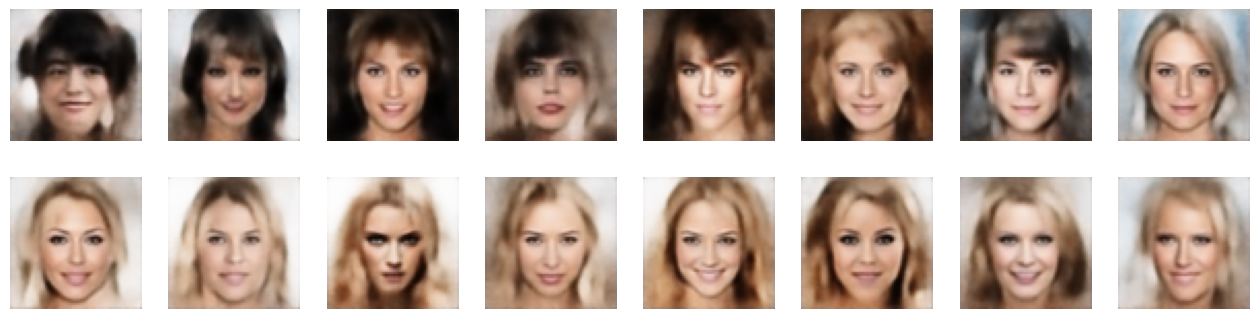

In [11]:
faces_ae = muestrear(decoder, gmm_ae, N_SAMPLES, AE_T, seed=SEED)       # (200, 64, 64, 3) en [0, 1]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, img in zip(axes.flat, faces_ae):
    ax.imshow(img); ax.axis("off")
plt.show()

## 8. CSV para Kaggle (AE)

In [12]:
guardar_csv(faces_ae, "submission_final_ae.csv")

submission_final_ae.csv guardado | shape: (200, 4097)


## 9. FID local (AE)

In [13]:
fid_csv_ae = fid_del_csv("submission_final_ae.csv")                                       # el CSV que subimos (200 imágenes)
fid_1000_ae = fid_local(muestrear(decoder, gmm_ae, N_FID, AE_T, seed=SEED + 2))           # muestra nueva, no la de la búsqueda
fid_1000_ae_k1 = min(v for (K, T), v in resultados_ae.items() if K == 1)                  # una sola gaussiana, para comparar

print(f"FID local del CSV (200 imgs):                      {fid_csv_ae:.1f}")
print(f"FID local con {N_FID} imgs (K={AE_K}, T={AE_T}, muestra nueva):  {fid_1000_ae:.1f}")
print(f"FID local con {N_FID} imgs (una sola gaussiana, K=1):  {fid_1000_ae_k1:.1f}")
print(f"Referencia reales (200 imgs):                      {fid_suelo:.1f}")
print(f"Referencia ruido  (200 imgs):                      {fid_ruido:.1f}")

/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


FID local del CSV (200 imgs):                      95.0
FID local con 1000 imgs (K=24, T=0.8, muestra nueva):  78.2
FID local con 1000 imgs (una sola gaussiana, K=1):  89.6
Referencia reales (200 imgs):                      35.8
Referencia ruido  (200 imgs):                      582.4


# Parte B. Variational Autoencoder (VAE)

Misma red base, mismo decoder, misma pérdida de reconstrucción, mismo entrenamiento y mismo muestreo que el AE. Lo que cambia es el final del encoder y la pérdida.

## 10. Modelo

- **Encoder**: la red base de la sección 3 y, en lugar de una sola `Dense`, dos cabezas de 128: `z_mean` y `z_log_var`. La capa `Sampling` saca `z = z_mean + sigma * epsilon` (**reparameterization trick**: así el gradiente llega a `z_mean` y a `z_log_var`).
- **Decoder**: el mismo que el del AE.
- **Pérdida**: reconstrucción (la común) + `beta` · KL, donde la KL mide lo que se aleja `N(z_mean, sigma^2)` de `N(0, I)` (forma cerrada).
- **`beta = 0,001`**: la KL pesa muy poco. Al final del entrenamiento la KL se queda en ~717 mientras la reconstrucción baja a ~171, es decir, el latente no se parece a `N(0, I)` (en un VAE de libro con `beta = 1` sí). Por eso no generamos con `z ~ N(0, I)`, sino que ajustamos una mezcla de gaussianas a los latentes, igual que en el AE.
- Al predecir, el modelo usa `z_mean` (sin ruido), no el `z` muestreado.

Esto no es un VAE estándar (la pérdida de reconstrucción y `beta` se han ajustado para que genere mejor), y también hay que decirlo en la presentación.

In [14]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim), mean=0.0, stddev=1.0)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon


vae_enc_in = layers.Input(shape=(64, 64, 3), name="encoder_input")
h = cuerpo_encoder(vae_enc_in)                                  # red base común: 64x64x3 -> 512

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)             # 512 -> 128
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)       # 512 -> 128
z_vae = Sampling()([z_mean, z_log_var])

encoder_vae = keras.Model(vae_enc_in, [z_mean, z_log_var, z_vae], name="encoder_vae")
decoder_vae = crear_decoder("decoder_vae")

encoder_vae.summary()
decoder_vae.summary()

Model: "encoder_vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 32, 32,    │      3,072 │ encoder_input[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_97[0][0]   │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_98 (Conv2D)  │ (None, 16, 16,    │    131,072 │ leaky_re_lu_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_98[0][0]   │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_99 (Conv2D)  │ (None, 8, 8, 256) │    524,288 │ leaky_re_lu_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 8, 8, 256) │        512 │ conv2d_99[0][0]   │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 8, 8, 256) │          0 │ group_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16384)     │          0 │ leaky_re_lu_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 512)       │  8,389,120 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 128)       │     65,664 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 128)       │     65,664 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 128)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,179,776 (35.02 MB)

 Trainable params: 9,179,776 (35.02 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder_vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16384)          │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_9           │ (None, 8, 8, 256)      │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_10          │ (None, 16, 16, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_11          │ (None, 32, 32, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 64, 64, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,756,483 (10.52 MB)

 Trainable params: 2,756,483 (10.52 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=0.001, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta

        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.rec_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        latent = z if training else z_mean
        return self.decoder(latent, training=training)

    @tf.function
    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            reconstruction = self.decoder(z, training=True)

            rec_loss = perdida_reconstruccion(tf.convert_to_tensor(x), tf.convert_to_tensor(reconstruction))

            kl_loss = -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = rec_loss + (self.beta * kl_loss)

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.rec_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.rec_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    @tf.function
    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        reconstruction = self.decoder(z, training=False)

        rec_loss = perdida_reconstruccion(tf.convert_to_tensor(x), tf.convert_to_tensor(reconstruction))

        kl_loss = -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
        kl_loss = tf.reduce_mean(kl_loss)

        total_loss = rec_loss + (self.beta * kl_loss)

        self.total_loss_tracker.update_state(total_loss)
        self.rec_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.rec_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }


vae = VAE(encoder_vae, decoder_vae, beta=0.001)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=LR))

## 11. Entrenamiento

Mismos lotes, épocas y callbacks que el AE. El `loss` es la pérdida total (reconstrucción + `beta` · KL) y se muestran también por separado `reconstruction_loss` y `kl_loss`. La `reconstruction_loss` es directamente comparable con la pérdida de entrenamiento del AE.

Epoch 1/50


210/211 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - kl_loss: 889.8231 - loss: 558.0251 - reconstruction_loss: 557.1353

211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - kl_loss: 889.4884 - loss: 557.5178 - reconstruction_loss: 556.6283

211/211 ━━━━━━━━━━━━━━━━━━━━ 30s 102ms/step - kl_loss: 819.1977 - loss: 450.9867 - reconstruction_loss: 450.1676 - val_kl_loss: 848.2815 - val_loss: 332.0657 - val_reconstruction_loss: 331.2174 - learning_rate: 2.0000e-04
Epoch 2/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - kl_loss: 834.5490 - loss: 302.2835 - reconstruction_loss: 301.4488 - val_kl_loss: 831.1677 - val_loss: 279.7771 - val_reconstruction_loss: 278.9460 - learning_rate: 2.0000e-04
Epoch 3/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - kl_loss: 832.8266 - loss: 267.5304 - reconstruction_loss: 266.6975 - val_kl_loss: 824.5991 - val_loss: 257.6812 - val_reconstruction_loss: 256.8566 - learning_rate: 2.0000e-04
Epoch 4/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - kl_loss: 837.2974 - loss: 249.5836 - reconstruction_loss: 248.7462 - val_kl_loss: 837.7661 - val_loss: 245.4617 - val_reconstruction_loss: 244.6239 - learning_rate: 2.0000e-04
Epoch 5/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - kl_loss: 826.5017 - loss: 

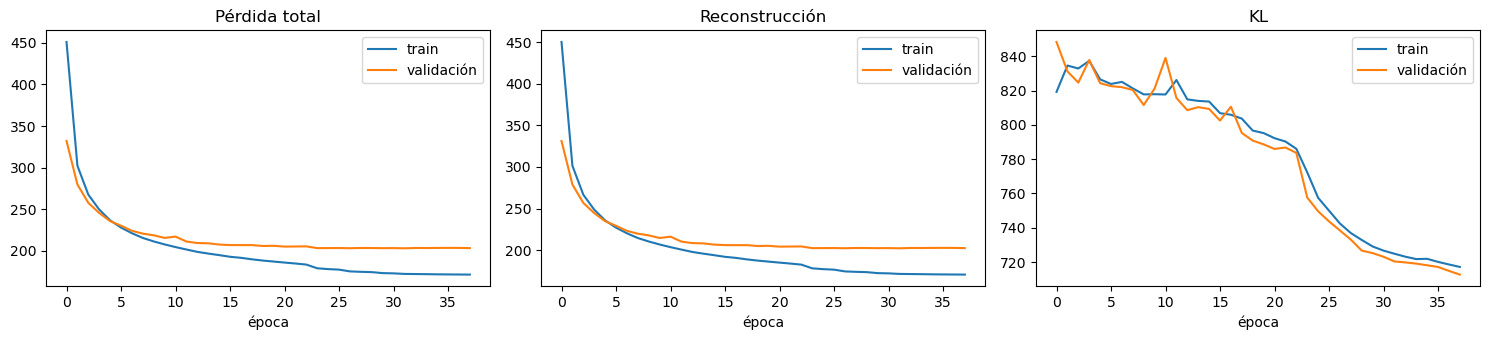

In [16]:
history_vae = vae.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks_comunes(),
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, k, t in zip(axes, ["loss", "reconstruction_loss", "kl_loss"], ["Pérdida total", "Reconstrucción", "KL"]):
    ax.plot(history_vae.history[k], label="train")
    ax.plot(history_vae.history["val_" + k], label="validación")
    ax.set_title(t); ax.set_xlabel("época"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Reconstrucciones

Arriba la imagen original de validación, abajo lo que reconstruye el VAE (con `z_mean`).

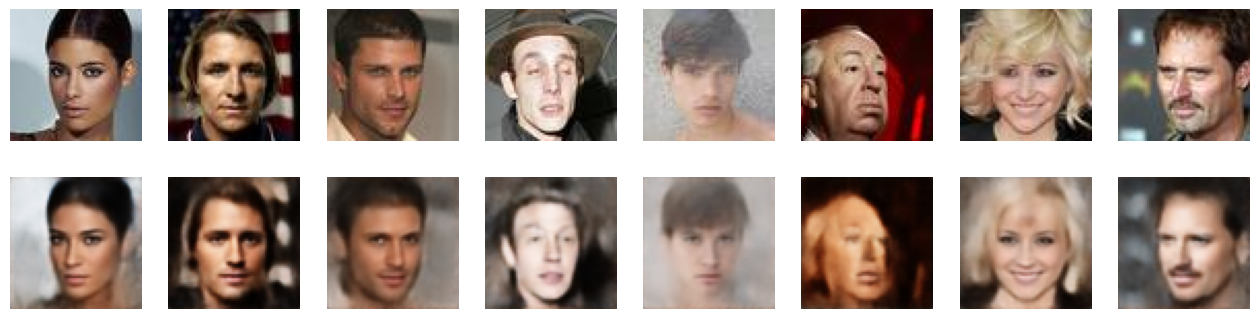

In [17]:
z_mean_val = encoder_vae.predict(x_val[:8], verbose=0)[0]
rec_v = decoder_vae.predict(z_mean_val, verbose=0)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(x_val[i]); axes[1, i].imshow(np.clip(rec_v[i], 0, 1))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.show()

## 13. Generar caras

Mismo muestreo que en el AE, ahora con los `z_mean` de las 27.000 imágenes de train.

In [18]:
z_vae_train = encoder_vae.predict(x_train, batch_size=256, verbose=0)[0]
print("Latentes de train:", z_vae_train.shape)

gmm_vae, VAE_K, VAE_T, resultados_vae = buscar_muestreo(decoder_vae, z_vae_train)

Latentes de train: (27000, 128)
K= 1  T=0.7  ->  FID(1000) = 90.94
K= 1  T=0.8  ->  FID(1000) = 89.75
K= 1  T=0.9  ->  FID(1000) = 89.81
K= 1  T=1.0  ->  FID(1000) = 90.64


/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


K= 8  T=0.7  ->  FID(1000) = 80.71
K= 8  T=0.8  ->  FID(1000) = 79.95
K= 8  T=0.9  ->  FID(1000) = 80.37
K= 8  T=1.0  ->  FID(1000) = 81.30


/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


K=24  T=0.7  ->  FID(1000) = 78.40
K=24  T=0.8  ->  FID(1000) = 78.11
K=24  T=0.9  ->  FID(1000) = 78.83
K=24  T=1.0  ->  FID(1000) = 80.07

>>> Mejor configuración: K=24, T=0.8  (FID 78.11) <<<


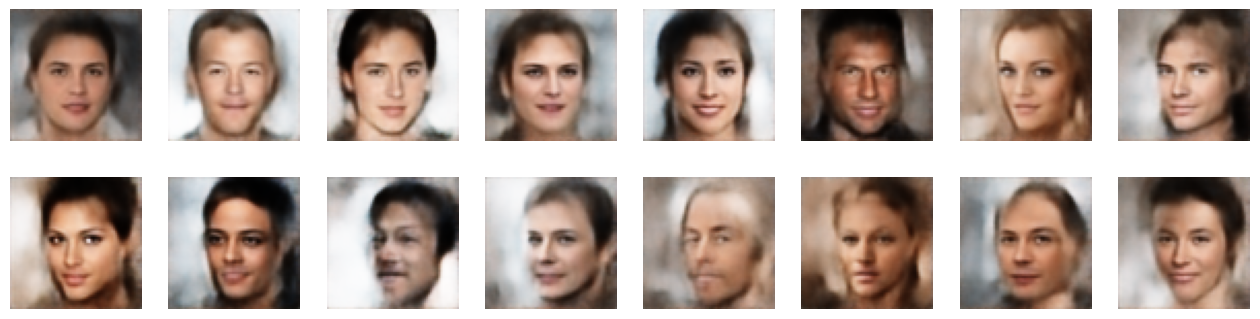

In [19]:
faces_vae = muestrear(decoder_vae, gmm_vae, N_SAMPLES, VAE_T, seed=SEED)       # (200, 64, 64, 3) en [0, 1]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, img in zip(axes.flat, faces_vae):
    ax.imshow(img); ax.axis("off")
plt.show()

## 14. CSV para Kaggle (VAE)

Mismo formato que el del AE: `ID` y 4096 píxeles en gris, sin `Usage`, forma `(200, 4097)`.

In [20]:
guardar_csv(faces_vae, "submission_final_vae.csv")

submission_final_vae.csv guardado | shape: (200, 4097)


## 15. FID local (VAE)

In [21]:
fid_csv_vae = fid_del_csv("submission_final_vae.csv")                                     # el CSV que subimos (200 imágenes)
fid_1000_vae = fid_local(muestrear(decoder_vae, gmm_vae, N_FID, VAE_T, seed=SEED + 2))    # muestra nueva, no la de la búsqueda
fid_1000_vae_k1 = min(v for (K, T), v in resultados_vae.items() if K == 1)                # una sola gaussiana, para comparar

print(f"FID local del CSV (200 imgs):                      {fid_csv_vae:.1f}")
print(f"FID local con {N_FID} imgs (K={VAE_K}, T={VAE_T}, muestra nueva):  {fid_1000_vae:.1f}")
print(f"FID local con {N_FID} imgs (una sola gaussiana, K=1):  {fid_1000_vae_k1:.1f}")
print(f"Referencia reales (200 imgs):                      {fid_suelo:.1f}")
print(f"Referencia ruido  (200 imgs):                      {fid_ruido:.1f}")

/home/sanru/miniforge3/envs/ds_env/lib/python3.10/site-packages/sklearn/mixture/_base.py:443: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  rng.multivariate_normal(mean, covariance, int(sample))


FID local del CSV (200 imgs):                      95.2
FID local con 1000 imgs (K=24, T=0.8, muestra nueva):  76.7
FID local con 1000 imgs (una sola gaussiana, K=1):  89.7
Referencia reales (200 imgs):                      35.8
Referencia ruido  (200 imgs):                      582.4


# Parte C. Comparación, fusión de caras y registro

## 16. Comparación AE vs VAE

Los dos modelos tienen la misma red base, pérdida de reconstrucción, entrenamiento y muestreo, y se miden con el mismo reparto de datos y la misma función de FID. Para comparar reconstrucciones usamos dos métricas calculadas igual en los dos sobre toda la validación: el **MSE por píxel** y la **pérdida de reconstrucción** con la que entrenan.

,MSE por píxel (val),Pérdida reconstrucción (val),FID CSV (200),FID (1000),"FID (1000), una gaussiana",Muestreo elegido
AE,0.0087,201.0271,94.9544,78.1501,89.6139,"K=24, T=0.8"
VAE,0.0088,202.3403,95.2134,76.7374,89.7490,"K=24, T=0.8"


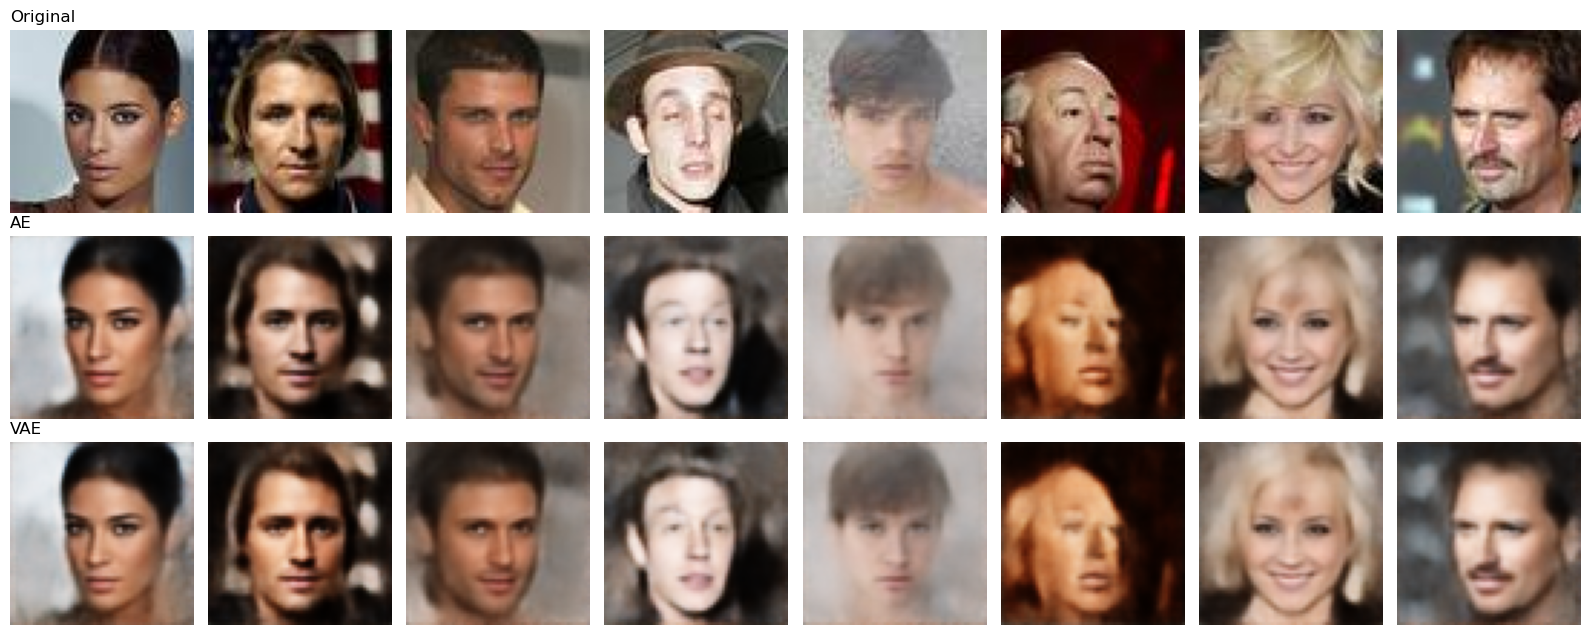

In [22]:
rec_ae_val = autoencoder.predict(x_val, batch_size=128, verbose=0)
rec_vae_val = decoder_vae.predict(encoder_vae.predict(x_val, batch_size=256, verbose=0)[0], batch_size=256, verbose=0)

def perdida_en_lotes(x_real, x_rec, lote=250):
    """Pérdida de reconstrucción media sobre todo el conjunto, por lotes para no llenar la GPU."""
    return float(np.mean([perdida_reconstruccion(tf.constant(x_real[i:i + lote]), tf.constant(x_rec[i:i + lote])).numpy()
                          for i in range(0, len(x_real), lote)]))


tabla = pd.DataFrame({
    "MSE por píxel (val)": [np.mean((x_val - rec_ae_val) ** 2), np.mean((x_val - rec_vae_val) ** 2)],
    "Pérdida reconstrucción (val)": [perdida_en_lotes(x_val, rec_ae_val), perdida_en_lotes(x_val, rec_vae_val)],
    "FID CSV (200)": [fid_csv_ae, fid_csv_vae],
    f"FID ({N_FID})": [fid_1000_ae, fid_1000_vae],
    f"FID ({N_FID}), una gaussiana": [fid_1000_ae_k1, fid_1000_vae_k1],
    "Muestreo elegido": [f"K={AE_K}, T={AE_T}", f"K={VAE_K}, T={VAE_T}"],
}, index=["AE", "VAE"])
display(tabla.round(4))

# Original / AE / VAE
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for i in range(8):
    for fila, img in enumerate([x_val[i], rec_ae_val[i], rec_vae_val[i]]):
        axes[fila, i].imshow(np.clip(img, 0, 1)); axes[fila, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("AE", loc="left"); axes[2, 0].set_title("VAE", loc="left")
plt.tight_layout(); plt.show()

## 17. Fusión de caras

Mezclamos dos caras en el espacio latente del VAE: codificamos las dos con `z_mean`, interpolamos entre sus latentes y decodificamos. Comparamos tres formas de interpolar (`t` va de 0 = cara A a 1 = cara B):

- **Lineal**: `(1 - t) · zA + t · zB`. Es la interpolación de clase. En dimensiones altas el punto medio de dos vectores tiene menos módulo que los `z` típicos, así que puede caer en una zona rara del latente.
- **Slerp**: interpolación esférica de la dirección y lineal del módulo, para que la mezcla conserve un módulo parecido al de los `z` reales.
- **Slerp blanqueado**: antes de interpolar se "blanquea" el espacio latente con la media y la covarianza de las caras reales (queda ~`N(0, I)`, donde el módulo sí es comparable entre dimensiones), se interpola ahí y se deshace el blanqueo.

Slerp y el blanqueo no salen en clase; son mejoras del autor del VAE sobre la lineal. En nuestras fotos las tres filas salen casi iguales a simple vista, así que no podemos afirmar que mejoren a la interpolación lineal.

Para cumplir el enunciado hay que usar **fotos de personas que no estén en el dataset** (por ejemplo los profesores): definir `img_A` e `img_B` con `cargar_foto(...)`. La foto tiene que ser un recorte cuadrado de la cara, con un encuadre parecido al del dataset (cara centrada, algo de pelo), porque si no la reconstrucción sale mal. Mientras no se cambien, usamos dos caras de validación.

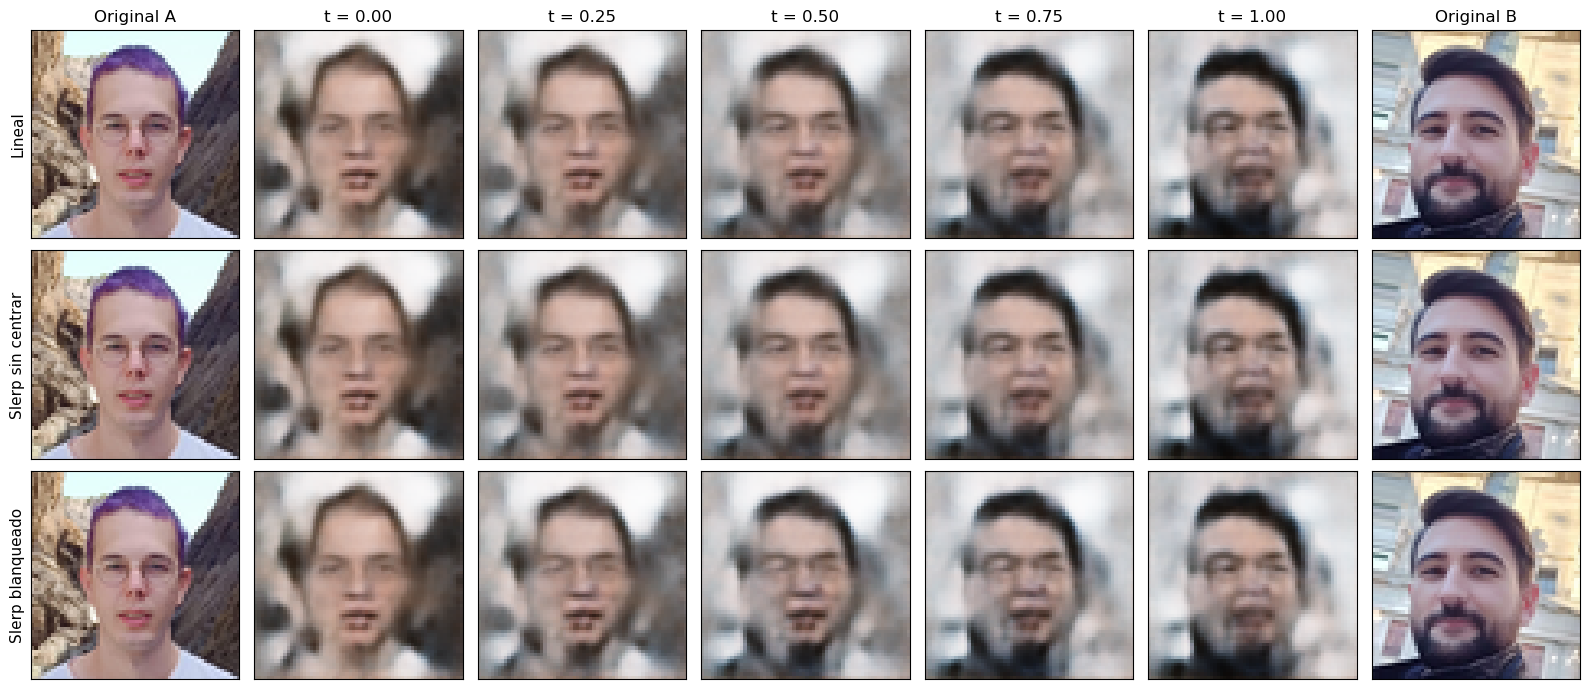

In [25]:
from PIL import Image


def cargar_foto(ruta):
    """Foto -> (64, 64, 3) en [0, 1]. Recorta el cuadrado central y reduce a 64x64: el encuadre de la cara hay que cuidarlo a mano."""
    im = Image.open(ruta).convert("RGB")
    lado = min(im.size)
    izq, arr = (im.size[0] - lado) // 2, (im.size[1] - lado) // 2
    im = im.crop((izq, arr, izq + lado, arr + lado)).resize((64, 64), Image.LANCZOS)
    return np.asarray(im, dtype="float32") / 255.0


# Caras a mezclar. Para el enunciado, sustituir por fotos que NO estén en el dataset:
img_A = cargar_foto("foto_A.jpg")
img_B = cargar_foto("foto_B.jpg")

# img_A = x_val[10]
# img_B = x_val[20]
z_mean_AB, _, _ = encoder_vae.predict(np.array([img_A, img_B]), verbose=0)
z_A, z_B = z_mean_AB

# --- Estadísticos del espacio latente de caras reales ---
mu_z = z_vae_train.mean(axis=0)
w, V = np.linalg.eigh(np.cov(z_vae_train, rowvar=False))
w = np.clip(w, 1e-6, None)
W = V @ np.diag(1.0 / np.sqrt(w)) @ V.T          # blanqueo: la distribución pasa a ser ~N(0, I)
W_inv = V @ np.diag(np.sqrt(w)) @ V.T
blanquear = lambda z: (z - mu_z) @ W
desblanquear = lambda u: u @ W_inv + mu_z


def slerp(t, a, b):
    """Dirección por interpolación esférica; módulo por interpolación lineal (vale con normas distintas)."""
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    ua, ub = a / na, b / nb
    omega = np.arccos(np.clip(np.dot(ua, ub), -1.0, 1.0))
    if np.sin(omega) < 1e-6:
        d = (1 - t) * ua + t * ub
    else:
        d = (np.sin((1 - t) * omega) * ua + np.sin(t * omega) * ub) / np.sin(omega)
    return d * ((1 - t) * na + t * nb)


metodos = {
    "Lineal": lambda t: (1 - t) * z_A + t * z_B,
    "Slerp sin centrar": lambda t: slerp(t, z_A, z_B),
    "Slerp blanqueado": lambda t: desblanquear(slerp(t, blanquear(z_A), blanquear(z_B))),
}
ts = [0.0, 0.25, 0.5, 0.75, 1.0]

zs = np.array([f(t) for f in metodos.values() for t in ts], dtype="float32")
caras = np.clip(decoder_vae.predict(zs, verbose=0), 0.0, 1.0)

fig, axs = plt.subplots(len(metodos), len(ts) + 2, figsize=(16, 7))
for r, nombre in enumerate(metodos):
    axs[r, 0].imshow(np.clip(img_A, 0, 1)); axs[r, 0].set_title("Original A" if r == 0 else "")
    axs[r, -1].imshow(np.clip(img_B, 0, 1)); axs[r, -1].set_title("Original B" if r == 0 else "")
    for j, t in enumerate(ts):
        axs[r, j + 1].imshow(caras[r * len(ts) + j])
        if r == 0:
            axs[r, j + 1].set_title(f"t = {t:.2f}")
    axs[r, 0].set_ylabel(nombre, fontsize=11)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 19. Conclusiones

**Resultado principal.** Con las mismas decisiones de diseño, el AE y el VAE dan resultados prácticamente iguales (los dos entrenados desde cero, unos 6 minutos cada uno):

| | AE | VAE |
|---|---|---|
| MSE por píxel (validación) | 0,0087 | 0,0088 |
| FID del CSV (200 imágenes) | 95,0 | 95,2 |
| FID con 1000 imágenes (`K` = 24, `T` = 0,8) | 78,2 | 76,7 |
| FID con 1000 imágenes (una sola gaussiana) | 89,6 | 89,7 |

Las diferencias (0,3 en el CSV y 1,4 en el FID de 1000) son pequeñas. Con un solo entrenamiento de cada modelo y un FID que se mueve 2-3 puntos de una muestra a otra (lo medimos con 200 imágenes en pruebas anteriores), **no podemos decir que uno sea mejor que el otro**. No hemos repetido el entrenamiento con otras semillas, así que no sabemos cuánto varía el resultado entre ejecuciones.

**Por qué salen iguales.** Con `beta = 0,001` la KL pesa menos del 1 % de la pérdida (`beta · KL` ≈ 0,7 de una pérdida de ~203). Aunque el VAE muestrea `z` con ruido al entrenar, en la práctica se comporta casi como un AE, y su latente no se parece a `N(0, I)`: por eso no se puede generar con `z ~ N(0, I)` y los dos modelos necesitan ajustar una mezcla de gaussianas a los latentes. Un VAE más fiel a la teoría (generar sacando `z ~ N(0, I)`) pediría una `beta` mayor, que no hemos probado aquí.

**Lo que sí mejora el resultado es el muestreo.** Pasar de una sola gaussiana a una mezcla de 24 baja el FID de 1000 imágenes de ~90 a ~77-78 en los dos modelos (un 13-14 %).

**Análisis visual**
- *Reconstrucciones*: conservan pose, expresión, color de piel y pelo, pero pierden el detalle fino (textura del pelo, fondo, objetos) y salen borrosas. Algunas caras se reconstruyen mal: en la figura de la sección 16, la sexta (un hombre mayor) sale con otro tono y la cara girada, en los dos modelos por igual.
- *Caras generadas*: plausibles y con variedad (género, pelo, fondo), pero suaves y sin detalles finos. Con `T = 0,8` se ganan caras más típicas a costa de algo de variedad.
- *Fusión de caras*: con dos fotos fuera del dataset, recortadas a mano para parecerse al encuadre de CelebA, el VAE reconstruye rasgos generales (color y forma del pelo, gafas, barba) muy borrosos, y la mezcla a mitad de camino es una cara plausible con rasgos de las dos. Lineal, slerp y slerp blanqueado dan resultados casi idénticos a simple vista.

**Límites**
- Imágenes de 64x64 y borrosidad: con la pérdida SSIM + L1 salen menos suaves que con MSE, pero sigue siendo visible.
- Dependencia del encuadre: CelebA está alineado y centrado, y una foto real sin recortar no se reconstruye (con el recorte central de la foto salía una cara irreconocible).
- `K` y `T` se eligen con el mismo FID que luego se informa, así que el valor elegido es algo optimista (por eso reevaluamos con una muestra nueva).